# 한국어 임베딩과 캐시

**이 노트북에서 할 일**

1. 05절과 같은 설정으로 E01.pdf 2쪽 글을 문서 청크 여섯 개로 나눕니다.
2. 글 하나와 글 목록을 임베딩해 받은 벡터의 숫자 개수를 봅니다.
3. 벡터를 파일에 저장해 두고 같은 글을 두 번 요청해 견줍니다.

**준비물** — 프로젝트 맨 위 폴더의 `.env` 파일에 `OPENAI_API_KEY`가 있어야 합니다.
임베딩 요청은 모두 여섯 번이고, 답을 쓰는 모델은 부르지 않습니다.
보낼 조각 수는 2498개 어림입니다.

예상 비용은 여섯 번을 합쳐 0.001달러 미만입니다.
임베딩 요금은 OpenAI 모델 안내(2026-09-17 확인)에 적힌 100만 토큰당 0.02달러입니다.
실행 시간은 패키지 설치를 빼면 20초 안팎입니다.

데이터는 01·02·05·06절과 같은 파일 하나입니다.
폴더 `labs/data/rag-corpus/pdf/easy/`의 `E01.pdf` 2쪽입니다.
벡터를 저장할 폴더는 실행할 때마다 새로 만드는 빈 임시 폴더입니다.

**강의와 실습 범위** — 강의 시간에는 4~6절을 설명합니다.
글 하나 임베딩하기, 글 목록 임베딩하기, 차원 수 줄이기입니다.
7절 벡터 캐시와 8절 값 바꿔 보기, 9·10절 실패와 수정은 함께 실행하고 실습 시간에 다시 읽습니다.
2절은 01·05절과 같은 코드라 강의에서 빠르게 확인합니다.

**기준 버전** — 실습 폴더에 고정한 패키지 판을 씁니다.
pypdf 6.18.0과 langchain-core 1.6.2를 씁니다.
나누기 도구는 langchain-text-splitters 1.1.2입니다.
임베딩은 langchain-openai 1.6.0으로 부릅니다.
벡터 캐시는 langchain-classic 1.0.8이고 조각은 tiktoken 0.14.0으로 셉니다.

교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 버전과 Windows·macOS에서는 이번에 실행하지 않았습니다.

실습 폴더 `labs/part3/ch10-document-processing`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 내려가는 흐름도로 맨 위 초록 상자 E01.pdf 2쪽 글 905자 재귀 방식 문서 청크 6개 185와 147과 86과 164와 130과 188자에서 두 갈래로 갈라져 왼쪽은 보라 상자 text-embedding-3-small 기본 설정과 노란 상자 벡터 6개 숫자 1536개씩으로 내려간 뒤 초록 상자 벡터 캐시 폴더 저장 파일 6개와 노란 상자 두 번째 요청 저장 파일 6개 그대로 두 벡터 목록이 같음으로 이어지고 오른쪽은 보라 상자 text-embedding-3-small 차원 수 256을 준 설정과 노란 상자 벡터 1개 숫자 256개로 끝남](attachment:07-1-벡터와-캐시.png)

위에서 아래로 보고 가운데에서 두 갈래로 갈라집니다.
맨 위 초록 상자가 05절과 같은 설정으로 나눈 문서 청크이고, 보라 상자가 이번에 요청을 보낸 임베딩 모델입니다.
왼쪽 갈래는 기본 설정이고 오른쪽 갈래는 차원 수 256을 준 설정입니다.
왼쪽 갈래의 벡터만 캐시 폴더에 저장했습니다.
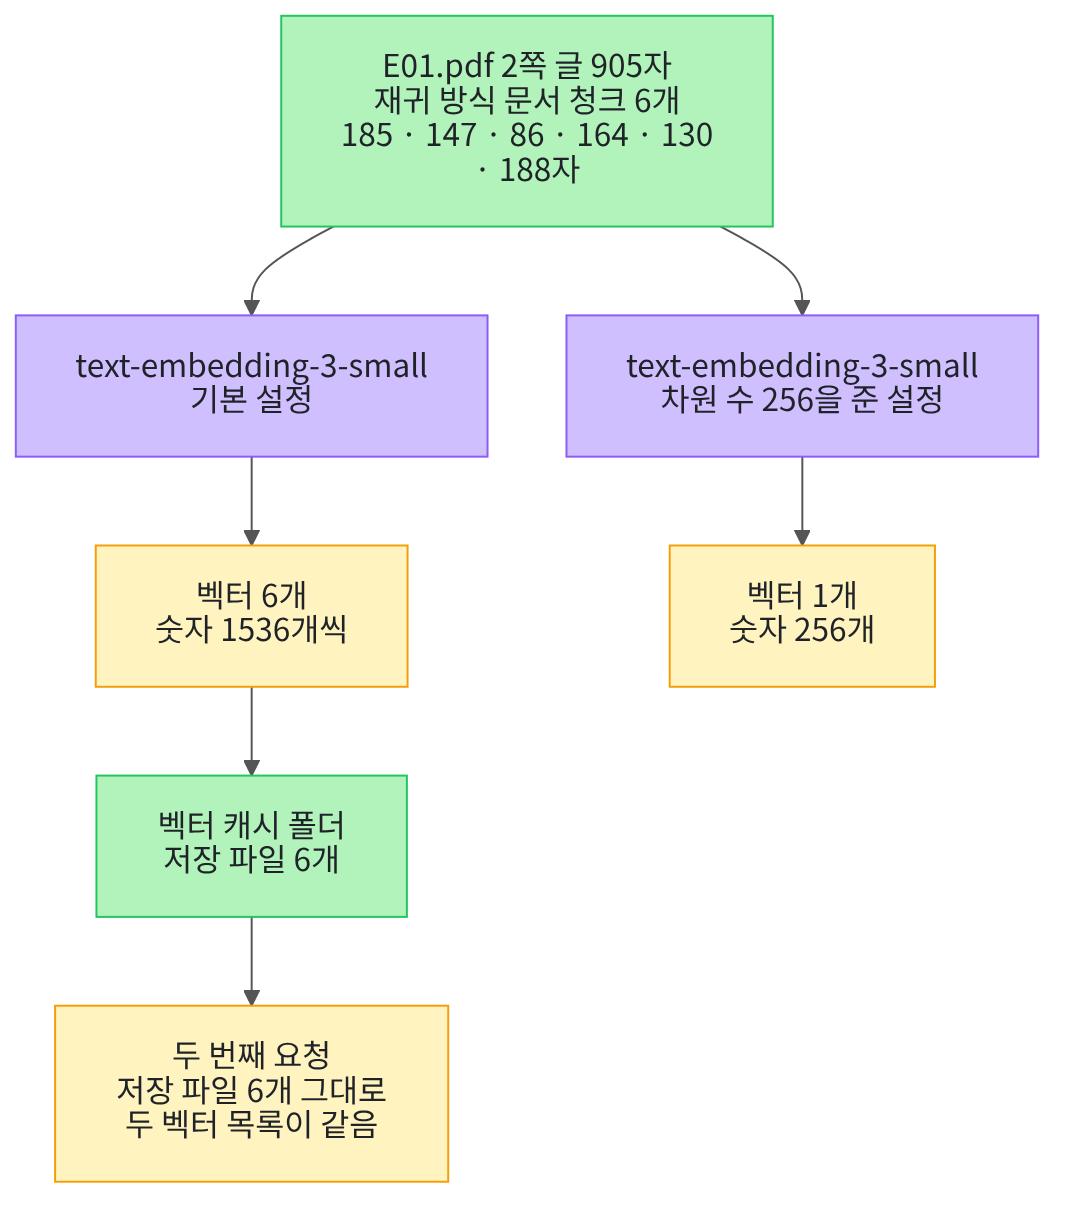

## 1. 준비

첫 셀은 패키지를 설치하고 설치된 버전을 출력합니다. 설치에는 몇십 초가 걸릴 수 있습니다.
05·06절에서 쓴 도구에, 벡터를 파일에 저장하는 도구를 더해 설치합니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "pypdf==6.18.0" "langchain-core==1.6.2" "langchain-text-splitters==1.1.2" "langchain-openai==1.6.0" "langchain-classic==1.0.8" "tiktoken==0.14.0" "python-dotenv==1.2.3"
from importlib.metadata import version

print("pypdf:", version("pypdf"))
print("langchain-core:", version("langchain-core"))
print("langchain-text-splitters:", version("langchain-text-splitters"))
print("langchain-openai:", version("langchain-openai"))
print("langchain-classic:", version("langchain-classic"))
print("tiktoken:", version("tiktoken"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.


pypdf: 6.18.0
langchain-core: 1.6.2
langchain-text-splitters: 1.1.2
langchain-openai: 1.6.0
langchain-classic: 1.0.8
tiktoken: 0.14.0
python-dotenv: 1.2.3


**결과 읽기** — 출력 일곱 줄 가운데 첫 줄은 `pypdf: 6.18.0`입니다.
넷째 줄 `langchain-openai: 1.6.0`과 다섯째 줄 `langchain-classic: 1.0.8`도 보세요.
준비물에 적은 기준 버전과 같습니다.

다음 셀은 이 절에서 쓸 이름을 불러옵니다.
클래스 `OpenAIEmbeddings`가 임베딩을 부르는 객체를 만듭니다.
클래스 `CacheBackedEmbeddings`와 `LocalFileStore`가 벡터를 파일에 저장하는 도구입니다.

앞에서 배운 함수는 `rag_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.
이 노트북은 Ch 9 02절 `load_pdf_pages()`, 05절 `make_length_list()`, Ch 8 01절 `count_tokens()`를 가져옵니다.

In [2]:
# 나누기·임베딩·벡터 저장·조각 세기에 쓸 이름을 불러옵니다
import os
import tempfile

from langchain_classic.embeddings import CacheBackedEmbeddings
from langchain_classic.storage import LocalFileStore
from langchain_openai import OpenAIEmbeddings
from langchain_text_splitters import RecursiveCharacterTextSplitter
import tiktoken
# Ch 9 02절, 05절, Ch 8 01절 함수 세 개를 도구 파일에서 가져옵니다
from rag_tools import count_tokens, load_pdf_pages, make_length_list

**결과 읽기** — 이 셀은 이름을 불러오기만 하므로 출력이 없습니다.

모듈 `tempfile`은 Python에 들어 있는 기능 묶음입니다.
이 절에서는 벡터를 저장할 빈 임시 폴더를 만드는 데 씁니다.
Ch 1·2 준비 셀에서 연습 폴더를 만들 때 쓴 것과 같은 모듈입니다.

다음 셀은 키가 있는지 확인합니다. 키 값은 출력하지 않고 있는지만 봅니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


**결과 읽기** — 출력 줄은 `OPENAI_API_KEY 설정 여부: True`입니다.

## 2. 벡터로 바꿀 재료 얻기

01~06절과 같은 방법으로 프로젝트 맨 위 경로를 고릅니다.
후보 세 개를 차례로 확인하고, 있는 경로에서 멈춥니다.

실행 전에 예상합니다. 프로젝트 맨 위에서 열었다면 첫째 후보를 고를 것입니다.

In [4]:
# 작업 폴더에서 본 프로젝트 맨 위 경로를 후보 세 개 가운데에서 고릅니다
candidates = [".", "../../..", "../../../.."]
root_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/labs/data/rag-corpus"):
        root_path = candidate
        break
print("고른 경로:", root_path)
assert root_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

고른 경로: .


**결과 읽기** — 출력 줄은 `고른 경로: .`입니다. `assert`도 통과했습니다.
교재 출력은 프로젝트 맨 위를 작업 폴더로 삼아 실행해서 첫째 후보를 골랐습니다.

준비 셀에서 가져온 Ch 9 02절 로더 함수 `load_pdf_pages()`는 PDF 경로와 문서 이름을 받아 쪽마다 `Document` 하나를 만듭니다.

다음 셀은 이 함수로 E01.pdf를 읽고 2쪽 본문을 이 절의 재료로 삼습니다.
05·06절과 같은 글이고 같은 이름 `plain_text`에 담습니다.

In [5]:
# E01.pdf를 쪽마다 읽고 2쪽 본문을 이 절에서 벡터로 바꿀 재료로 삼습니다
corpus_path = root_path + "/labs/data/rag-corpus"
pdf_path = corpus_path + "/pdf/easy/E01.pdf"
pages = load_pdf_pages(pdf_path, "E01")
plain_text = pages[1].page_content
print("Document 수:", len(pages))
print("나눌 글의 글자 수:", len(plain_text))

Document 수: 5
나눌 글의 글자 수: 905


**결과 읽기** — 출력 첫 줄은 `Document 수: 5`이고 다음 줄은 `나눌 글의 글자 수: 905`입니다.
05·06절에서 본 값과 같은 글입니다.

문서 청크 길이는 준비 셀에서 가져온 05절 `make_length_list()`로 셉니다.

다음 셀은 05절 4절과 같은 설정으로 이 글을 나눕니다.
끊을 자리 순서와 목표 크기 200자, 겹침 0을 그대로 씁니다.
같은 설정을 쓰는 까닭은 06절이 예고한 대로 「그 문서 청크를 벡터로 바꾸는 단계」를 보는 것이기 때문입니다.

In [6]:
# 05절 4절과 같은 설정으로 2쪽 글을 문서 청크 여섯 개로 나눕니다
separator_order = ["\n\n", ". ", "\n", " ", ""]
recursive_splitter = RecursiveCharacterTextSplitter(
    separators=separator_order,
    chunk_size=200,
    chunk_overlap=0,
    keep_separator="end",
)
chunk_texts = recursive_splitter.split_text(plain_text)
print("문서 청크 수:", len(chunk_texts))
print("문서 청크별 문자 수:", make_length_list(chunk_texts))

문서 청크 수: 6
문서 청크별 문자 수: [185, 147, 86, 164, 130, 188]


**결과 읽기** — 출력 첫 줄은 `문서 청크 수: 6`입니다.
다음 줄은 `문서 청크별 문자 수: [185, 147, 86, 164, 130, 188]`입니다.
05절 4절 재귀 방식 결과와 같은 값입니다.

## 3. 요청 수와 비용 어림하기

요청을 보내기 전에 얼마를 보내는지 셉니다. Ch 9 03절과 06절에서 한 방법과 같습니다.
먼저 05·06절과 같은 조각 세는 규칙을 준비합니다. 조각 수는 준비 셀에서 가져온 `count_tokens()`로 셉니다.

In [7]:
# 05·06절과 같은 조각 세는 규칙을 준비합니다
encoding = tiktoken.get_encoding("cl100k_base")
print("조각 세는 규칙 이름:", encoding.name)

조각 세는 규칙 이름: cl100k_base


**결과 읽기** — 출력 줄은 `조각 세는 규칙 이름: cl100k_base`입니다.
Ch 9 02절에서 이 임베딩 모델의 조각 세는 규칙으로 확인한 이름과 같습니다.

다음 셀은 이 절이 보낼 조각 수를 어림합니다.
글 목록을 보내는 요청이 두 번이고, 글 하나를 보내는 요청이 네 번입니다.
글 목록 요청은 글 전체를 보내는 것과 거의 같으니 글 전체의 조각 수로 셉니다.

In [8]:
# 이 절이 보낼 조각 수를 요청 전에 어림합니다
one_text = chunk_texts[0]
whole_tokens = count_tokens(encoding, plain_text)
one_tokens = count_tokens(encoding, one_text)
list_requests = 2
one_requests = 4
sent_tokens = whole_tokens * list_requests + one_tokens * one_requests
print("글 전체의 조각 수:", whole_tokens)
print("첫 문서 청크의 조각 수:", one_tokens)
print("이 절이 보낼 조각 수 어림:", sent_tokens)

글 전체의 조각 수: 869
첫 문서 청크의 조각 수: 190
이 절이 보낼 조각 수 어림: 2498


**결과 읽기** — 출력 첫 줄은 `글 전체의 조각 수: 869`이고 05절에서 센 값과 같습니다.
다음 줄은 `첫 문서 청크의 조각 수: 190`입니다.
마지막 줄은 `이 절이 보낼 조각 수 어림: 2498`입니다.

다음 셀은 그 조각 수로 비용을 어림합니다. 요금은 100만 조각당 0.02달러입니다.
아주 작은 값이라 `round()`로 소수 일곱째 자리까지 줄입니다.

In [9]:
# 보낼 조각 수로 이 절의 임베딩 비용을 요청 전에 어림합니다
embedding_rate = 0.02
tokens_per_million = 1000000
raw_cost = sent_tokens * embedding_rate / tokens_per_million
total_cost = round(raw_cost, 7)
print("100만 조각당 요금(달러):", embedding_rate)
print("이 절 전체의 비용 어림(달러):", total_cost)

100만 조각당 요금(달러): 0.02
이 절 전체의 비용 어림(달러): 5e-05


**결과 읽기** — 출력 마지막 줄은 `이 절 전체의 비용 어림(달러): 5e-05`입니다.
표기 `e-05`는 06절에서 본 것과 같습니다. 곧 0.00005달러입니다.
코드로 센 어림이고 청구 금액이 아닙니다.

## 4. 글 하나를 벡터로 바꾸기

Ch 9 03절과 같은 이름으로 임베딩 객체를 만듭니다.
모델 이름도 Ch 9·06절과 같은 `text-embedding-3-small`입니다.
차원 수는 따로 주지 않습니다. Ch 9가 만든 색인과 같은 설정으로 이어 쓰려는 것입니다.

In [10]:
# Ch 9 03절과 같은 이름으로 임베딩 객체를 만듭니다(요청은 보내지 않습니다)
embedding_model_name = "text-embedding-3-small"
embedding_model = OpenAIEmbeddings(model=embedding_model_name)
print("임베딩 모델 이름:", embedding_model.model)
print("차원 수를 주었는가:", embedding_model.dimensions is not None)

임베딩 모델 이름: text-embedding-3-small
차원 수를 주었는가: False


**결과 읽기** — 출력 두 줄은 `임베딩 모델 이름: text-embedding-3-small`과 `차원 수를 주었는가: False`입니다.
차원 수를 주지 않았으니 이 모델의 기본값으로 만듭니다.

이 노트북의 임베딩 출력은 2026-09-21에 이 모델로 실행한 결과입니다.
같은 글을 다시 보내면 벡터의 소수 아래 자리가 조금 달라질 수 있습니다.
그래서 이 노트북은 숫자 값 자체를 출력하지 않고 개수와 자료형만 봅니다.

다음 셀은 첫 문서 청크 하나만 임베딩합니다.
메서드 `embed_documents()`는 글 목록을 받아 같은 순서의 벡터 목록을 반환합니다.
대괄호 `[0]`은 그 목록에서 첫 벡터를 고르는 표기입니다.

In [11]:
# 첫 문서 청크 하나만 임베딩해 받은 벡터의 숫자 개수를 봅니다(임베딩 요청 1번)
one_vectors = embedding_model.embed_documents([one_text])
single_vector = one_vectors[0]
print("보낸 글의 글자 수:", len(one_text))
print("받은 벡터 수:", len(one_vectors))
print("벡터의 숫자 개수:", len(single_vector))
print("첫 숫자의 자료형:", type(single_vector[0]).__name__)

보낸 글의 글자 수: 185
받은 벡터 수: 1
벡터의 숫자 개수: 1536
첫 숫자의 자료형: float


**결과 읽기** — 출력 첫 줄은 `보낸 글의 글자 수: 185`이고 다음 줄은 `받은 벡터 수: 1`입니다.
셋째 줄은 `벡터의 숫자 개수: 1536`이고 마지막 줄은 `첫 숫자의 자료형: float`입니다.

글 185자가 소수 1536개로 바뀌었습니다. 이 개수가 이 모델의 기본 **차원 수**입니다.
Ch 9 03절과 06절 색인도 차원 수를 주지 않았으니 같은 1536개입니다.
Ch 5 02절 로컬 모델은 384개였습니다. 모델이 다르면 개수도 다릅니다.

## 5. 글 목록을 한 번에 바꾸기

메서드 `embed_documents()`에 글 목록을 주면 벡터 목록이 돌아옵니다.
먼저 벡터마다 숫자 개수를 모으는 함수를 만듭니다.

In [12]:
# 벡터 목록을 받아 벡터마다 숫자 개수를 순서대로 모아 반환합니다
def make_size_list(vectors):
    sizes = []
    for vector in vectors:
        sizes.append(len(vector))
    return sizes

**결과 읽기** — 이 셀은 함수를 만들기만 하므로 출력이 없습니다.

05절 `make_length_list()`는 글의 문자 수를 셌고 이 함수는 벡터의 숫자 개수를 셉니다.
모양은 같고 세는 대상만 다릅니다.
다음 셀은 문서 청크 여섯 개를 한 번에 임베딩합니다.

In [13]:
# 문서 청크 여섯 개를 한 번에 임베딩해 보낸 글 수와 받은 벡터 수를 견줍니다(임베딩 요청 1번)
all_vectors = embedding_model.embed_documents(chunk_texts)
print("보낸 글 수:", len(chunk_texts))
print("받은 벡터 수:", len(all_vectors))
print("벡터마다 숫자 개수:", make_size_list(all_vectors))
print("첫 벡터가 앞의 결과와 같은 개수인가:", len(all_vectors[0]) == len(single_vector))

보낸 글 수: 6
받은 벡터 수: 6
벡터마다 숫자 개수: [1536, 1536, 1536, 1536, 1536, 1536]
첫 벡터가 앞의 결과와 같은 개수인가: True


**결과 읽기** — 출력 첫 줄과 둘째 줄은 `보낸 글 수: 6`과 `받은 벡터 수: 6`입니다.
셋째 줄은 `벡터마다 숫자 개수: [1536, 1536, 1536, 1536, 1536, 1536]`입니다.
마지막 줄은 `첫 벡터가 앞의 결과와 같은 개수인가: True`입니다.

보낸 글 수와 받은 벡터 수가 같고 순서도 같습니다.
요청은 한 번입니다. 이 라이브러리는 글을 1000개씩 묶어 한 요청에 보냅니다.
글마다 요청을 따로 보내지 않으므로 목록으로 모아 보내는 쪽이 요청 수가 적습니다.

## 6. 벡터의 숫자 개수 줄이기

**차원 수**는 벡터에 든 숫자의 개수입니다.
한 사람을 키와 몸무게 두 값으로 적을 수도 있고 열 값으로 자세히 적을 수도 있습니다.
인자 `dimensions`에 숫자를 주면 그 개수만큼만 담은 벡터가 돌아옵니다.

Ch 9 03절과 06절 색인은 이 인자를 주지 않아 기본값 1536개였습니다.
이 절에서만 256을 주어 개수가 어떻게 달라지는지 봅니다.

실행 전에 예상합니다. 같은 글이지만 숫자 개수가 256개로 줄 것입니다.

In [14]:
# 같은 모델에 차원 수 256을 주고 같은 글을 임베딩합니다(임베딩 요청 1번)
short_dimensions = 256
short_model = OpenAIEmbeddings(model=embedding_model_name, dimensions=short_dimensions)
short_vectors = short_model.embed_documents([one_text])
print("준 차원 수:", short_dimensions)
print("기본 설정 벡터의 숫자 개수:", len(single_vector))
print("차원 수를 준 벡터의 숫자 개수:", len(short_vectors[0]))

준 차원 수: 256
기본 설정 벡터의 숫자 개수: 1536
차원 수를 준 벡터의 숫자 개수: 256


**결과 읽기** — 출력 첫 줄은 `준 차원 수: 256`입니다.
다음 두 줄은 `기본 설정 벡터의 숫자 개수: 1536`과 `차원 수를 준 벡터의 숫자 개수: 256`입니다.

같은 모델과 같은 글인데 숫자 개수가 1536개에서 256개로 줄었습니다.
숫자가 적으면 저장 자리와 견주는 셈이 줄어듭니다.
그 대신 두 벡터는 서로 견줄 수 없습니다. 숫자 개수가 다르면 같은 자리의 값끼리 짝이 맞지 않습니다.

어느 차원 수가 검색에 더 나은지는 이 절에서 재지 않았습니다.
그것은 질문 여러 개로 검색까지 돌려 봐야 아는 값입니다.

## 7. 벡터를 파일에 저장해 두고 다시 읽기

**벡터 캐시**는 한 번 만든 벡터를 파일에 저장해 두고 같은 글이 다시 오면 그 파일을 읽는 저장소입니다.
Ch 9 벡터스토어는 검색을 위해 벡터를 담는 곳이라 하는 일이 다릅니다.
먼저 이번 실행에서만 쓸 빈 폴더를 만듭니다.

In [15]:
# 이번 실행에서만 쓸 빈 임시 폴더를 만들어 벡터를 저장할 자리로 삼습니다
cache_folder = tempfile.mkdtemp(prefix="ch10-07-")
folder_names = os.listdir(cache_folder)
print("폴더 안의 파일 수:", len(folder_names))
print("빈 폴더인가:", folder_names == [])

폴더 안의 파일 수: 0
빈 폴더인가: True


**결과 읽기** — 출력 두 줄은 `폴더 안의 파일 수: 0`과 `빈 폴더인가: True`입니다.

함수 `mkdtemp()`는 빈 폴더를 새로 만들어 그 경로를 글로 반환합니다.
폴더 경로는 실행할 때마다 달라지므로 출력하지 않았습니다.
빈 폴더에서 시작해야 저장 전과 저장 뒤의 차이를 볼 수 있습니다.

다음 셀은 임베딩 모델과 파일 저장소를 이어 벡터 캐시를 만듭니다.
**가르는 이름**은 저장한 벡터를 설정마다 갈라 두려고 파일 이름 앞에 붙이는 글입니다.
인자 `key_encoder`에 준 `sha256`은 Ch 7 08절에서 파일 지문을 만든 그 방법입니다.

In [16]:
# 임베딩 모델과 파일 저장소를 이어 벡터 캐시를 만듭니다(요청은 보내지 않습니다)
cache_name = "text-embedding-3-small-1536-"
byte_store = LocalFileStore(cache_folder)
cached_embeddings = CacheBackedEmbeddings.from_bytes_store(
    embedding_model, byte_store, namespace=cache_name, key_encoder="sha256",
)
print("가르는 이름:", cache_name)
print("벡터 캐시의 자료형:", type(cached_embeddings).__name__)

가르는 이름: text-embedding-3-small-1536-
벡터 캐시의 자료형: CacheBackedEmbeddings


**결과 읽기** — 출력 첫 줄은 `가르는 이름: text-embedding-3-small-1536-`입니다.
다음 줄은 `벡터 캐시의 자료형: CacheBackedEmbeddings`입니다.

가르는 이름에 모델 이름과 차원 수를 함께 적었습니다. 두 값이 벡터를 가르는 설정이기 때문입니다.
이 이름은 사람이 정하는 글입니다. 라이브러리가 모델 설정을 보고 알아서 가르지는 않습니다.

다음 셀은 같은 문서 청크 목록을 두 번 요청합니다.
실행 전에 예상합니다. 첫 요청에서 파일이 여섯 개 생기고 두 번째 요청에서는 늘지 않을 것입니다.

In [17]:
# 같은 문서 청크 목록을 두 번 요청하고 저장 파일 수와 두 결과를 견줍니다(임베딩 요청 1번)
first_vectors = cached_embeddings.embed_documents(chunk_texts)
first_names = os.listdir(cache_folder)
second_vectors = cached_embeddings.embed_documents(chunk_texts)
second_names = os.listdir(cache_folder)
print("첫 요청 뒤 저장 파일 수:", len(first_names))
print("두 번째 요청 뒤 저장 파일 수:", len(second_names))
print("두 벡터 목록이 같은가:", first_vectors == second_vectors)

첫 요청 뒤 저장 파일 수: 6
두 번째 요청 뒤 저장 파일 수: 6
두 벡터 목록이 같은가: True


**결과 읽기** — 출력 첫 줄은 `첫 요청 뒤 저장 파일 수: 6`입니다.
다음 줄은 `두 번째 요청 뒤 저장 파일 수: 6`이고 마지막 줄은 `두 벡터 목록이 같은가: True`입니다.

문서 청크마다 파일 하나가 생겼습니다. 두 번째 요청에서는 파일이 늘지 않았습니다.
설치판 소스에서는 저장값이 없는 글만 모아 임베딩을 부릅니다.
모두 저장되어 있으면 요청을 한 번도 보내지 않습니다.

이 출력은 파일 수와 두 목록이 같다는 것까지만 보여 줍니다.
요청을 몇 번 보냈는지 이 셀에서 직접 세지는 않았습니다.

다음 셀은 저장 파일의 이름을 봅니다.
**저장 이름표**는 가르는 이름과 글로 만든 파일 이름입니다.

In [18]:
# 저장 파일 이름이 가르는 이름으로 시작하는지와 이름 길이를 봅니다
first_name = second_names[0]
starts_with_cache_name = first_name.startswith(cache_name)
print("첫 파일 이름이 가르는 이름으로 시작하는가:", starts_with_cache_name)
print("첫 파일 이름의 글자 수:", len(first_name))
print("가르는 이름의 글자 수:", len(cache_name))

첫 파일 이름이 가르는 이름으로 시작하는가: True
첫 파일 이름의 글자 수: 92
가르는 이름의 글자 수: 28


**결과 읽기** — 출력 첫 줄은 `첫 파일 이름이 가르는 이름으로 시작하는가: True`입니다.
다음 두 줄은 `첫 파일 이름의 글자 수: 92`와 `가르는 이름의 글자 수: 28`입니다.

92자에서 28자를 빼면 64자가 남습니다. 그 64자가 글로 만든 지문입니다.
Ch 7 08절에서 본 `sha256` 지문도 16진수 64자였습니다.
파일 이름 자체는 실행마다 같지만 지문이라 뜻을 읽을 수 없어 출력하지 않았습니다.

## 8. 값 하나만 바꿔 보기

바꾸는 값은 보낼 글 하나입니다. 첫 문서 청크 끝에 빈칸 하나만 더합니다.
가르는 이름과 모델은 그대로 둡니다.

실행 전에 예상합니다. 글이 달라졌으니 저장 이름표도 달라져 파일이 하나 늘 것입니다.

In [19]:
# 첫 문서 청크 끝에 빈칸 하나만 더해 같은 캐시에 요청합니다(임베딩 요청 1번)
changed_text = one_text + " "
changed_vectors = cached_embeddings.embed_documents([changed_text])
changed_names = os.listdir(cache_folder)
print("바꾼 글의 글자 수:", len(changed_text))
print("앞의 글과 글자까지 같은가:", changed_text == one_text)
print("저장 파일 수:", len(changed_names))
print("받은 벡터의 숫자 개수:", len(changed_vectors[0]))

바꾼 글의 글자 수: 186
앞의 글과 글자까지 같은가: False
저장 파일 수: 7
받은 벡터의 숫자 개수: 1536


**결과 읽기** — 출력 첫 줄은 `바꾼 글의 글자 수: 186`입니다.
다음 두 줄은 `앞의 글과 글자까지 같은가: False`와 `저장 파일 수: 7`입니다.
마지막 줄은 `받은 벡터의 숫자 개수: 1536`입니다.

빈칸 하나 때문에 다른 글이 되었고 파일이 하나 늘었습니다.
벡터 캐시는 글이 글자까지 같을 때만 저장한 값을 읽습니다.
글의 빈칸이나 줄바꿈을 알아서 정리해 주지는 않습니다.

읽어 온 글의 빈칸을 고치는 단계를 넣는다면 그 방법도 가르는 이름에 적어야 합니다.
같은 문서를 다르게 정리한 두 벡터가 한 이름 아래 섞이기 때문입니다.

## 9. 일부러 실패해 보기

색인을 만들다가 차원 수를 줄이기로 마음을 바꿨다고 생각해 보세요.
모델 객체만 바꾸고 가르는 이름은 앞에서 쓴 것을 그대로 둘 수 있습니다.

Before 셀은 「모델을 바꿨으니 돌아오는 벡터도 바뀔 것」이라고 보는 자리입니다.
차원 수 256 모델에 기본 설정의 가르는 이름을 그대로 붙여 같은 글을 요청합니다.

In [20]:
# 차원 수를 줄인 모델에 기본 설정의 가르는 이름을 그대로 붙여 같은 글을 요청합니다
wrong_cache = CacheBackedEmbeddings.from_bytes_store(
    short_model, byte_store, namespace=cache_name, key_encoder="sha256",
)
wrong_vectors = wrong_cache.embed_documents([one_text])
wrong_size = len(wrong_vectors[0])
wrong_names = os.listdir(cache_folder)
print("기대한 숫자 개수:", short_dimensions)
print("돌아온 벡터의 숫자 개수:", wrong_size)
print("두 값이 같은가:", wrong_size == short_dimensions)
print("저장 파일 수:", len(wrong_names))

기대한 숫자 개수: 256
돌아온 벡터의 숫자 개수: 1536
두 값이 같은가: False
저장 파일 수: 7


**결과 읽기** — 출력 첫 줄은 `기대한 숫자 개수: 256`입니다.
다음 줄 `돌아온 벡터의 숫자 개수: 1536`을 보세요. 기대한 개수가 아닙니다.
셋째 줄은 `두 값이 같은가: False`이고 마지막 줄은 `저장 파일 수: 7`입니다.

파일도 늘지 않았습니다. 같은 이름표의 파일이 이미 있어 저장한 값을 읽었기 때문입니다.
모델 객체는 바꿨지만 가르는 이름이 같아 4절에서 만든 1536개짜리 벡터가 돌아왔습니다.

이 벡터를 색인에 넣으면 차원 수가 섞입니다.
글은 맞고 개수만 틀리므로 오류 없이 지나갈 수 있습니다.

## 10. 고쳐서 다시 실행하기

가르는 이름에 차원 수를 넣어 앞 설정과 갈라 둡니다.
새 이름에는 저장한 파일이 없으니 모델이 벡터를 새로 만듭니다.

바뀌는 것은 가르는 이름 하나입니다. 모델과 글은 9절과 같습니다.

In [21]:
# 가르는 이름에 차원 수를 넣어 앞 설정의 벡터와 갈라 둡니다(임베딩 요청 1번)
short_cache_name = "text-embedding-3-small-256-"
short_cache = CacheBackedEmbeddings.from_bytes_store(
    short_model, byte_store, namespace=short_cache_name, key_encoder="sha256",
)
right_vectors = short_cache.embed_documents([one_text])
right_size = len(right_vectors[0])
right_names = os.listdir(cache_folder)
print("가르는 이름:", short_cache_name)
print("돌아온 벡터의 숫자 개수:", right_size)
print("두 값이 같은가:", right_size == short_dimensions)
print("저장 파일 수:", len(right_names))

가르는 이름: text-embedding-3-small-256-
돌아온 벡터의 숫자 개수: 256
두 값이 같은가: True
저장 파일 수: 8


**결과 읽기** — 출력 첫 줄은 `가르는 이름: text-embedding-3-small-256-`입니다.
다음 두 줄은 `돌아온 벡터의 숫자 개수: 256`과 `두 값이 같은가: True`입니다.
마지막 줄은 `저장 파일 수: 8`입니다.

기대한 개수가 돌아왔고 파일이 하나 늘었습니다. 새 이름 아래에 새 파일이 생긴 것입니다.
같은 글의 벡터 두 개가 폴더 안에 이름을 달리해 함께 있습니다.

가르는 이름에 넣을 값은 벡터를 가르는 설정입니다.
이 절에서는 모델 이름과 차원 수를 넣었습니다.
글을 정리하는 방법이나 문서와 질문에 붙이는 앞머리 글을 쓴다면 그것도 넣어야 합니다.

## 11. 정리

1. 05절과 같은 설정으로 나눈 문서 청크 여섯 개를 벡터로 바꿨습니다. 문자 수는 `[185, 147, 86, 164, 130, 188]`이었습니다.
2. 글 하나를 보내면 벡터 1개, 글 여섯 개를 보내면 벡터 6개가 돌아오고 순서도 같았습니다.
3. 기본 설정 벡터의 숫자 개수는 1536개이고, 차원 수 256을 주면 256개였습니다.
4. 같은 글을 두 번 요청하니 저장 파일 수가 6개 그대로였고 두 벡터 목록이 같았습니다.
5. 글 끝에 빈칸 하나를 더하니 다른 글이 되어 파일이 7개로 늘었습니다.
6. 같은 가르는 이름을 다시 쓰면 차원 수 256 모델에서도 1536개짜리 벡터가 돌아왔습니다.

다음 08절에서는 나누기와 임베딩 설정을 하나씩 바꿔 색인을 여러 벌 만듭니다.
설정마다 검색 결과가 어떻게 달라지는지 기록으로 남겨 견줍니다.
그때 이 절의 모델 이름과 차원 수가 실험 설정의 한 칸으로 다시 나옵니다.